# NeuroSentinel
### An ANN-Based Framework for Next-Day NIFTY 50 Log-Return Forecasting
Individual ESE project · CHRIST (Deemed to be University), Delhi NCR · Presentation 27 Oct 2026

## 1. Project overview and objectives
NeuroSentinel investigates whether a compact **GRU** neural network can forecast the next trading session's log return of the NIFTY 50 (`^NSEI`) better than simple benchmarks, on a strictly chronological out-of-sample test set.

**Objectives:** acquire & validate data → clean → engineer features → leakage-aware target → baselines → GRU → validation-based selection → untouched test evaluation → tests → diagnostics → saved artifacts → live inference (Streamlit `app.py`).

**Scope:** research prototype. No trading system, no profitability claim, no claim of significance beyond what the tests below show.

## 2. Research question and methodology
> Can a compact GRU forecast next-day NIFTY 50 log return more accurately than a zero-return baseline and a linear regression, out-of-sample?

Target: $y_t=\ln(C_{t+1}/C_t)$, using only information available at the close of session $t$. Models are compared on MAE, RMSE and directional accuracy. **A GRU that does not beat the baselines is a valid finding**, and the notebook reports whatever the run produces: no number in this notebook is typed in by hand.

## 3. Environment setup and imports

In [1]:
import json, random, platform, warnings, ast
from datetime import datetime, timedelta, timezone, time as dtime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, scipy, yfinance as yf
import tensorflow as tf
import keras
from keras import layers, regularizers
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
            "tensorflow": tf.__version__, "keras": keras.__version__, "yfinance": yf.__version__}
VERSIONS

{'python': '3.13.16',
 'numpy': '2.5.4',
 'pandas': '3.1.0',
 'sklearn': '1.9.1',
 'tensorflow': '2.21.0',
 'keras': '3.15.1',
 'yfinance': '1.7.0'}

## 4. Configuration and reproducibility
All intended settings from the specification live in one dictionary. Seeds are set per experiment with `keras.utils.set_random_seed`. TensorFlow training is **not guaranteed bit-for-bit reproducible** across hardware/software; seeds reduce but do not eliminate variation.

In [2]:
CFG = dict(
    ticker="^NSEI", start="2013-02-01",
    lookback=20, gru_units=32, dropout=0.2, dense_units=16, l2=1e-4,
    batch_size=64, lr=1e-3, patience=8, max_epochs=80,
    optimizers=["adam", "rmsprop"], losses=["mse", "huber"], seeds=[0, 1, 2],
    train_frac=0.70, val_frac=0.15, high_vol_quantile=0.75,
)
FEATURES = (["ret_lag_0", "ret_lag_1", "ret_lag_2", "ret_lag_3", "ret_lag_4",
             "vol_5", "vol_10", "vol_20", "mom_5", "mom_10", "mom_20",
             "hl_range", "oc_return", "vol_ratio"])
L = CFG["lookback"]
IST = timezone(timedelta(hours=5, minutes=30))
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
random.seed(0); np.random.seed(0); keras.utils.set_random_seed(0)
print(len(FEATURES), "features;", len(CFG["optimizers"]) * len(CFG["losses"]) * len(CFG["seeds"]), "planned experiments")

14 features; 12 planned experiments


## 5. Live data acquisition
Data come from Yahoo Finance via `yfinance` (`^NSEI`, daily bars). The download is **live**, so the final date depends on when the notebook runs. The raw download is saved to `artifacts/raw_data_snapshot.csv` so the exact data behind a run is on record (and is the dashboard's clearly-labelled fallback if the network fails).

In [3]:
def fetch_nifty(ticker, start):
    raw = yf.download(ticker, start=start, auto_adjust=False, progress=False)
    if raw is None or raw.empty:
        raise RuntimeError("Provider returned no data")
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    return raw

RETRIEVED_AT = datetime.now(IST).strftime("%Y-%m-%d %H:%M:%S IST")
raw = fetch_nifty(CFG["ticker"], CFG["start"])
raw.to_csv(ART / "raw_data_snapshot.csv")
print("Retrieved:", RETRIEVED_AT)
print("Columns  :", raw.columns.tolist())
print("Rows     :", len(raw), "| first:", raw.index.min().date(), "| last:", raw.index.max().date())
print(raw.dtypes.to_string())
print("\nMissing values per column:\n", raw.isna().sum().to_string())
raw.tail()

Retrieved: 2026-10-26 19:33:56 IST
Columns  : ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
Rows     : 3373 | first: 2013-02-01 | last: 2026-10-26
Price
Adj Close    float64
Close        float64
High         float64
Low          float64
Open         float64
Volume         int64

Missing values per column:
 Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2026-10-19,22888.949219,22888.949219,23175.250000,22845.000000,23150.849609,285800
2026-10-21,22811.349609,22811.349609,23120.900391,22649.900391,23016.000000,324700
2026-10-22,22687.650391,22687.650391,22785.000000,22554.849609,22687.750000,391600
2026-10-23,22600.000000,22600.000000,22787.250000,22372.000000,22742.199219,364200
2026-10-26,22753.199219,22753.199219,22753.199219,22387.349609,22524.400391,0


## 6. Raw-data inspection and cleaning
`clean_ohlcv` implements the checks in the specification and **returns a report**: duplicates, non-numeric/non-finite values, non-positive prices, OHLC consistency, volume handling. It never silently invents values.

* **Volume:** for an index, Yahoo's volume can be 0 on some sessions. A reported 0 is treated as *missing*, not as genuine zero trading, and is never used as real volume.
* **Incomplete session:** if the last bar is dated *today (IST)* and it is before 16:00 IST, it is an in-progress bar and is dropped, so the model never trains/evaluates on an unfinished candle.
* Rows with invalid prices are dropped (counted); OHLC inconsistencies are reported but kept (they are tiny provider rounding cases, not grounds for deleting a session).

In [4]:
def clean_ohlcv(raw, drop_incomplete_today=True):
    rep = {"raw_rows": len(raw)}
    df = raw.copy()
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    df = df[["Open", "High", "Low", "Close", "Volume"]].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan)
    rep["duplicate_dates"] = int(df.index.duplicated().sum())
    df = df[~df.index.duplicated(keep="last")].sort_index()
    px = ["Open", "High", "Low", "Close"]
    bad = df[px].isna().any(axis=1) | (df[px] <= 0).any(axis=1)
    rep["invalid_ohlc_rows_dropped"] = int(bad.sum())
    df = df[~bad]
    incons = (df["High"] < df[["Open", "Close", "Low"]].max(axis=1)) | (df["Low"] > df[["Open", "Close", "High"]].min(axis=1))
    rep["ohlc_inconsistent_rows_kept"] = int(incons.sum())
    rep["zero_or_missing_volume_rows"] = int((~(df["Volume"] > 0)).sum())
    df["Volume"] = df["Volume"].where(df["Volume"] > 0)
    now = datetime.now(IST)
    rep["incomplete_session_dropped"] = 0
    if drop_incomplete_today and len(df) and df.index[-1].date() == now.date() and now.time() < dtime(16, 0):
        df = df.iloc[:-1]
        rep["incomplete_session_dropped"] = 1
    rep["clean_rows"] = len(df)
    return df, rep

df, rep = clean_ohlcv(raw)
quality = pd.Series({**rep, "start": str(df.index.min().date()), "end": str(df.index.max().date()),
                     "index_monotonic_increasing": bool(df.index.is_monotonic_increasing)}, name="value")
print("DATA-QUALITY REPORT (from this execution)"); quality.to_frame()

DATA-QUALITY REPORT (from this execution)


,value
raw_rows,3373
duplicate_dates,0
invalid_ohlc_rows_dropped,0
ohlc_inconsistent_rows_kept,0
zero_or_missing_volume_rows,29
incomplete_session_dropped,0
clean_rows,3373
start,2013-02-01
end,2026-10-26
index_monotonic_increasing,True


## 7. Exploratory data analysis
EDA is **descriptive**. Patterns seen here do not prove returns are predictable, and no model setting is chosen from these plots or from the test period.

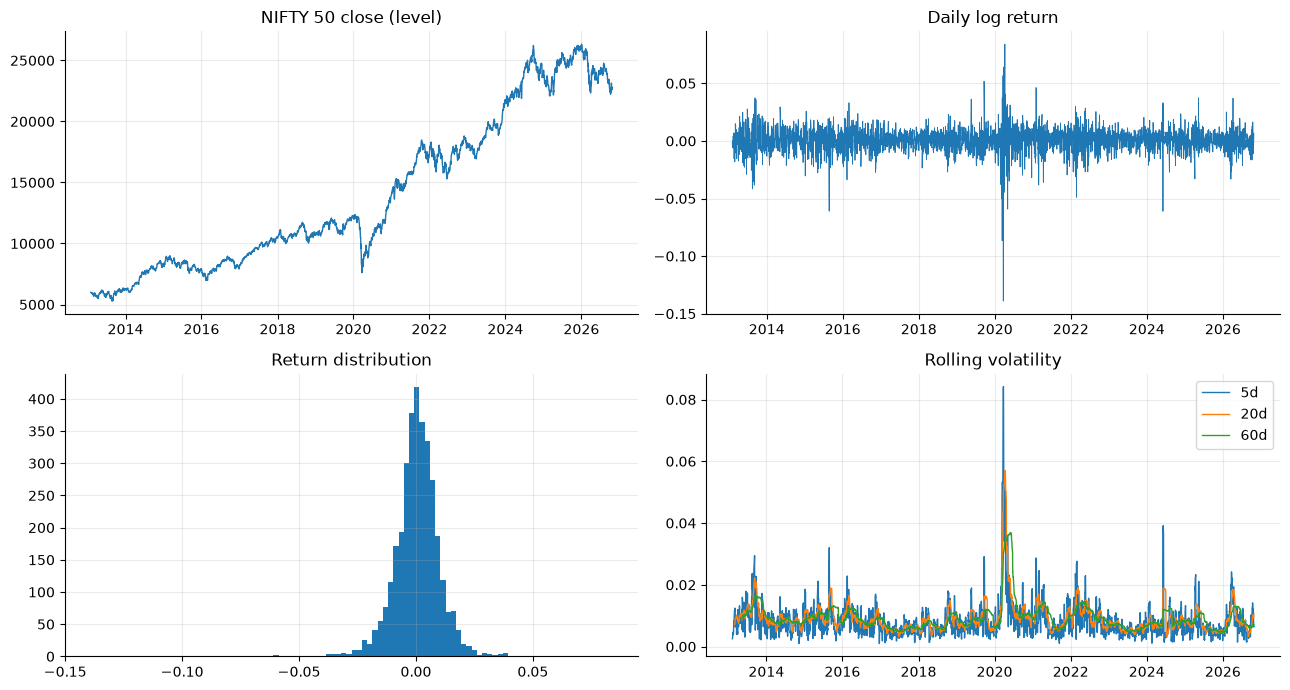

mean=0.00040  std=0.01021  skew=-1.13  excess kurtosis=17.25
Levels trend upward (non-stationary); returns hover around 0 with heavy tails and volatility clustering.


In [5]:
ret = np.log(df["Close"]).diff().dropna()
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax[0, 0].plot(df["Close"], lw=1); ax[0, 0].set_title("NIFTY 50 close (level)")
ax[0, 1].plot(ret, lw=0.6); ax[0, 1].set_title("Daily log return")
ax[1, 0].hist(ret, bins=100); ax[1, 0].set_title("Return distribution")
for w in (5, 20, 60):
    ax[1, 1].plot(ret.rolling(w).std(), lw=1, label=f"{w}d")
ax[1, 1].set_title("Rolling volatility"); ax[1, 1].legend()
plt.tight_layout(); plt.show()
print(f"mean={ret.mean():.5f}  std={ret.std():.5f}  skew={stats.skew(ret):.2f}  excess kurtosis={stats.kurtosis(ret):.2f}")
print("Levels trend upward (non-stationary); returns hover around 0 with heavy tails and volatility clustering.")

## 8. Feature engineering
Every feature at row $t$ uses data from sessions $\le t$ only. With $r_t=\ln(C_t/C_{t-1})$:

| Feature | Definition |
|---|---|
| `ret_lag_k` (k=0..4) | $r_{t-k}$ ; `ret_lag_0` is **today's** return (known at close of $t$) |
| `vol_w` (w=5,10,20) | rolling std of $r$ over the last $w$ sessions, including $t$ |
| `mom_w` (w=5,10,20) | $\ln(C_t / C_{t-w})$ (log-return momentum) |
| `hl_range` | $(H_t-L_t)/C_t$ |
| `oc_return` | $\ln(C_t/O_t)$ |
| `vol_ratio` | $V_t$ / mean of $V_{t-20..t-1}$ (**past only**); reported-zero volumes are missing; where the ratio is undefined it is set to neutral `1.0` |

Warm-up: the first 20 rows lack enough history for `vol_20`/`mom_20`, and are dropped explicitly.

In [6]:
def build_features(df, add_target=True):
    d = pd.DataFrame(index=df.index)
    c = df["Close"]
    r = np.log(c / c.shift(1))
    for k in range(5):
        d[f"ret_lag_{k}"] = r.shift(k)
    for w in (5, 10, 20):
        d[f"vol_{w}"] = r.rolling(w).std()
    for w in (5, 10, 20):
        d[f"mom_{w}"] = np.log(c / c.shift(w))
    d["hl_range"] = (df["High"] - df["Low"]) / c
    d["oc_return"] = np.log(c / df["Open"])
    v = df["Volume"].where(df["Volume"] > 0)
    ref = v.shift(1).rolling(20, min_periods=10).mean()
    d["vol_ratio"] = (v / ref).fillna(1.0)
    if add_target:
        d["target"] = r.shift(-1)
    return d

feat_all = build_features(df)
assert list(feat_all.columns) == FEATURES + ["target"]
n_warm = int(feat_all[FEATURES].isna().any(axis=1).sum())
n_last = int(feat_all["target"].isna().sum())
print(f"rows: {len(feat_all)} | warm-up rows with incomplete features: {n_warm} | rows without a next-day target: {n_last} (the final session)")
feat_all.dropna(subset=FEATURES).tail(3)

rows: 3373 | warm-up rows with incomplete features: 20 | rows without a next-day target: 1 (the final session)


,ret_lag_0,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,vol_5,vol_10,vol_20,mom_5,mom_10,mom_20,hl_range,oc_return,vol_ratio,target
Date,,,,,,,,,,,,,,,
2026-10-22,-0.005437,-0.003396,-0.011174,0.006450,0.016425,0.010905,0.011728,0.01038,0.002867,0.003736,-0.027876,0.010144,-0.000004,1.159369,-0.003871
2026-10-23,-0.003871,-0.005437,-0.003396,-0.011174,0.006450,0.006360,0.010290,0.01028,-0.017429,0.016426,-0.036784,0.018374,-0.006272,1.055209,0.006756
2026-10-26,0.006756,-0.003871,-0.005437,-0.003396,-0.011174,0.006480,0.009710,0.00984,-0.017123,0.010282,-0.013528,0.016079,0.010107,1.000000,NaN


## 9. Target construction and leakage prevention
$y_t=\ln(C_{t+1}/C_t)$ is `r.shift(-1)`: the return **after** the feature row. The final session has no target (tomorrow is unknown), so it is excluded from supervised data but is exactly the row used for live inference.

Three distinct kinds of NaN are handled differently: raw-source gaps (dropped & reported in §6), rolling warm-up (first rows dropped), and the forward-looking target (last row, kept only for inference).

Leakage controls: chronological split (no shuffling across time), scaler fitted on training rows only, and a **future-perturbation test** in §17 that corrupts all data after $t$ and proves the features at $t$ do not change.

In [7]:
data = feat_all.dropna(subset=FEATURES).dropna(subset=["target"])
print("supervised rows:", len(data), "|", data.index[0].date(), "->", data.index[-1].date())

supervised rows: 3352 | 2013-03-01 -> 2026-10-23


## 10. Chronological train / validation / test split
Sample $j$ = a 20-session window ending at row $j+19$ with that row's target. The first 19 rows lack a full window, so they supply context only. Samples are split **70 / 15 / 15 in time order**. A window may reach back into an earlier split for *context* (legitimate: it is information known at that time), but the *target* date of each sample belongs to its split.

Boundary note: the last training target $y_t=\ln(C_{t+1}/C_t)$ ends on the first validation date's close. This is label overlap in the harmless direction (a validation input contains a training label); no training input ever sees validation/test data.

In [8]:
n_samples = len(data) - (L - 1)
n_tr = int(n_samples * CFG["train_frac"]); n_va = int(n_samples * CFG["val_frac"]); n_te = n_samples - n_tr - n_va
sample_dates = data.index[L - 1:]                       # date of the last row of each window = date t of the target
idx = {"train": np.arange(0, n_tr), "val": np.arange(n_tr, n_tr + n_va), "test": np.arange(n_tr + n_va, n_samples)}
split_table = pd.DataFrame({k: {"n": len(v), "start": str(sample_dates[v[0]].date()), "end": str(sample_dates[v[-1]].date())} for k, v in idx.items()}).T
split_table

,n,start,end
train,2333,2013-04-01,2022-10-03
val,499,2022-10-04,2024-10-14
test,501,2024-10-15,2026-10-23


## 11. Scaling and sequence construction
* The `StandardScaler` is fitted **only on feature rows up to the last training sample's date**.
* The GRU target is divided by the training-set std (`y_scale`) so MSE/Huber gradients are well-conditioned; predictions are multiplied back, and **all metrics are in original log-return units**. Huber's δ=1 is therefore in units of training-std.

In [9]:
Xdf = data[FEATURES]; y_all = data["target"].values
last_train_row = idx["train"][-1] + (L - 1)             # last data row whose date <= last training sample date
scaler = StandardScaler().fit(Xdf.values[: last_train_row + 1])
Xs = scaler.transform(Xdf.values)
y_scale = float(y_all[L - 1:][idx["train"]].std())

def make_sequences(Xs, y, L):
    Xq = np.stack([Xs[j: j + L] for j in range(len(Xs) - L + 1)])
    return Xq, y[L - 1:]

Xseq, yseq = make_sequences(Xs, y_all, L)
Xflat = Xseq[:, -1, :]                                   # same samples, current-row features only (for the linear baseline)
S = {k: dict(X=Xseq[v], Xf=Xflat[v], y=yseq[v], dates=sample_dates[v]) for k, v in idx.items()}
print("sequence tensor:", Xseq.shape, "| y_scale =", round(y_scale, 6))
for k, s in S.items():
    print(k, s["X"].shape, s["y"].shape)

sequence tensor: (3333, 20, 14) | y_scale = 0.011081
train (2333, 20, 14) (2333,)
val (499, 20, 14) (499,)
test (501, 20, 14) (501,)


## 12–13. Baselines and metrics
**Zero-return:** $\hat y_t=0$. **Linear regression:** OLS on the (scaled) current-row features, trained on the training split only.

Metrics: MAE, RMSE, and directional accuracy (DA). *DA definition:* fraction of samples with a **non-zero actual return** where `sign(pred) == sign(actual)`; a prediction of exactly 0 is never correct. For the zero baseline DA is undefined (it predicts no direction) and reported as NaN. DA is **not** profitability.

In [10]:
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    nz = y != 0
    da = np.nan if np.all(p == 0) else float(np.mean(np.sign(p[nz]) == np.sign(y[nz])))
    return {"MAE": float(np.mean(np.abs(y - p))), "RMSE": float(np.sqrt(np.mean((y - p) ** 2))), "DA": da}

lin = LinearRegression().fit(S["train"]["Xf"], S["train"]["y"])
base_pred = {k: {"Zero-return": np.zeros(len(s["y"])), "Linear regression": lin.predict(s["Xf"])} for k, s in S.items()}
pd.DataFrame({m: metrics(S["val"]["y"], p) for m, p in base_pred["val"].items()}).T.round(6).rename_axis("validation set")

,MAE,RMSE,DA
validation set,,,
Zero-return,0.00540,0.007535,NaN
Linear regression,0.00546,0.007650,0.5


## 14. GRU architecture
`Input(20, 14)` → `GRU(32)` → `Dropout(0.2)` → `Dense(16, ReLU)` → `Dense(1)`; L2 = 1e-4 on the GRU and dense kernels. A regression model: outputs a number, not buy/sell. The 20-session lookback is a modelling choice, not a claim that markets have a 20-day memory.

In [11]:
def build_gru(optimizer, loss, seed):
    keras.utils.set_random_seed(seed)
    reg = regularizers.l2(CFG["l2"])
    m = keras.Sequential([
        layers.Input((L, len(FEATURES))),
        layers.GRU(CFG["gru_units"], kernel_regularizer=reg),
        layers.Dropout(CFG["dropout"]),
        layers.Dense(CFG["dense_units"], activation="relu", kernel_regularizer=reg),
        layers.Dense(1),
    ])
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop}[optimizer](CFG["lr"])
    m.compile(optimizer=opt, loss=keras.losses.Huber(delta=1.0) if loss == "huber" else "mse")
    return m

build_gru("adam", "mse", 0).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,153 (20.13 KB)

 Trainable params: 5,153 (20.13 KB)

 Non-trainable params: 0 (0.00 B)

## 15. Training and early stopping
Validation loss is monitored; training stops after 8 epochs without improvement and the best weights are restored. Training windows are shuffled *within the training set* (each window is self-contained and already past-only, so this does not leak time).

In [12]:
def gru_predict(model, X):
    return model.predict(X, batch_size=512, verbose=0).ravel() * y_scale

def train_one(optimizer, loss, seed):
    m = build_gru(optimizer, loss, seed)
    cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["patience"], restore_best_weights=True)
    h = m.fit(S["train"]["X"], S["train"]["y"] / y_scale, validation_data=(S["val"]["X"], S["val"]["y"] / y_scale),
              epochs=CFG["max_epochs"], batch_size=CFG["batch_size"], callbacks=[cb], verbose=0)
    return m, pd.DataFrame(h.history).rename_axis("epoch").reset_index()

m0, h0 = train_one("adam", "mse", 0)
print("single run: epochs run =", len(h0), "| best epoch =", int(h0["val_loss"].idxmin()) + 1)

single run: epochs run = 20 | best epoch = 12


## 16. Experiment grid and validation-based selection
2 optimisers × 2 losses × 3 seeds = **12** configurations. The selection criterion is **validation RMSE** (original units). The test set is not touched here. Note that testing 12 configurations adds mild model-selection bias to the validation score.

In [13]:
rows, histories, models = [], [], {}
for opt in CFG["optimizers"]:
    for loss in CFG["losses"]:
        for seed in CFG["seeds"]:
            m, h = train_one(opt, loss, seed)
            pv, pt = gru_predict(m, S["val"]["X"]), gru_predict(m, S["train"]["X"])
            mv = metrics(S["val"]["y"], pv)
            cid = f"{opt}-{loss}-s{seed}"
            rows.append(dict(config=cid, optimizer=opt, loss=loss, seed=seed, epochs_run=len(h), best_epoch=int(h["val_loss"].idxmin()) + 1,
                             train_rmse=metrics(S["train"]["y"], pt)["RMSE"], val_rmse=mv["RMSE"], val_mae=mv["MAE"], val_da=mv["DA"]))
            histories.append(h.assign(config=cid)); models[cid] = m
            print(f"{cid:22s} epochs={len(h):3d} val_RMSE={mv['RMSE']:.6f}")

experiments = pd.DataFrame(rows).sort_values("val_rmse").reset_index(drop=True)
history_df = pd.concat(histories, ignore_index=True)
best_id = experiments.loc[0, "config"]; model = models[best_id]; best_row = experiments.loc[0]
experiments.round(6)

adam-mse-s0            epochs= 20 val_RMSE=0.007479


adam-mse-s1            epochs= 26 val_RMSE=0.007385


adam-mse-s2            epochs= 11 val_RMSE=0.007450


adam-huber-s0          epochs= 12 val_RMSE=0.007488


adam-huber-s1          epochs= 52 val_RMSE=0.007311


...

rmsprop-mse-s2         epochs= 10 val_RMSE=0.007432


rmsprop-huber-s0       epochs= 12 val_RMSE=0.007513


rmsprop-huber-s1       epochs= 45 val_RMSE=0.007338


rmsprop-huber-s2       epochs= 10 val_RMSE=0.007435


,config,optimizer,loss,seed,epochs_run,best_epoch,train_rmse,val_rmse,val_mae,val_da
0,adam-huber-s1,adam,huber,1,52,44,0.009483,0.007311,0.005273,0.566265
1,rmsprop-huber-s1,rmsprop,huber,1,45,37,0.009988,0.007338,0.005272,0.570281
2,adam-mse-s1,adam,mse,1,26,18,0.010071,0.007385,0.005342,0.518072
3,rmsprop-mse-s1,rmsprop,mse,1,28,20,0.010190,0.007395,0.005331,0.532129
4,rmsprop-mse-s2,rmsprop,mse,2,10,2,0.010947,0.007432,0.005261,0.586345
5,rmsprop-huber-s2,rmsprop,huber,2,10,2,0.011013,0.007435,0.005264,0.564257
6,adam-huber-s2,adam,huber,2,10,2,0.010987,0.007438,0.005281,0.586345
7,adam-mse-s2,adam,mse,2,11,3,0.010877,0.007450,0.005309,0.562249
8,adam-mse-s0,adam,mse,0,20,12,0.010425,0.007479,0.005370,0.548193
9,adam-huber-s0,adam,huber,0,12,4,0.010944,0.007488,0.005357,0.540161


SELECTED (lowest validation RMSE): adam-huber-s1


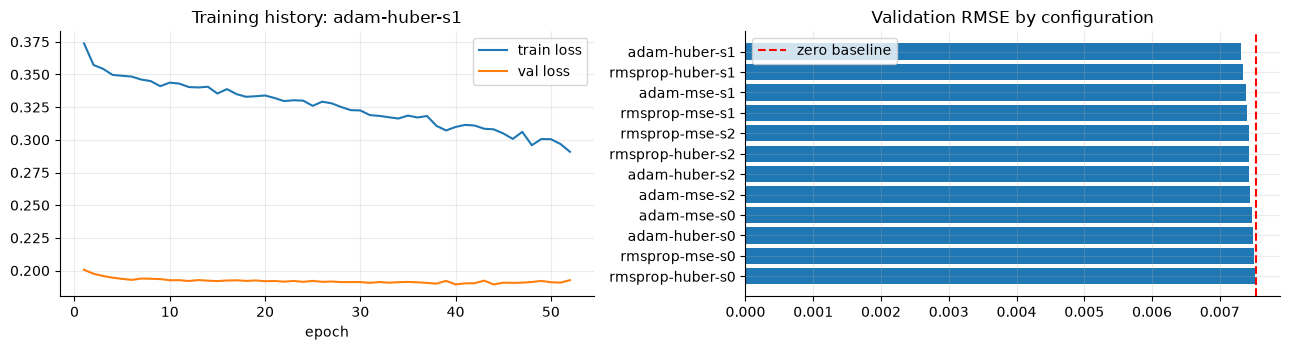

In [14]:
print("SELECTED (lowest validation RMSE):", best_id)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
hb = history_df[history_df.config == best_id]
ax[0].plot(hb["epoch"] + 1, hb["loss"], label="train loss"); ax[0].plot(hb["epoch"] + 1, hb["val_loss"], label="val loss")
ax[0].set_title(f"Training history: {best_id}"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].barh(experiments["config"][::-1], experiments["val_rmse"][::-1]); ax[1].set_title("Validation RMSE by configuration")
ax[1].axvline(metrics(S["val"]["y"], base_pred["val"]["Zero-return"])["RMSE"], color="r", ls="--", label="zero baseline"); ax[1].legend()
plt.tight_layout(); plt.show()

## 17. Testing and quality checks
Executable checks with visible pass/fail. Failures are recorded, not hidden. Artifact tests are appended in §21 after saving. The future-perturbation test is the key leakage test: it multiplies **all prices/volumes after a chosen date by random factors** and shows that features at and before that date are bit-identical.

In [15]:
TESTS = []
def run_test(group, name, fn):
    try:
        fn(); TESTS.append((group, name, "PASS", ""))
    except Exception as e:
        TESTS.append((group, name, "FAIL", f"{type(e).__name__}: {e}"))

# ---- data
def t_nonempty(): assert len(df) > 1000
def t_order(): assert df.index.is_monotonic_increasing
def t_dupes(): assert not df.index.duplicated().any()
def t_cols(): assert {"Open", "High", "Low", "Close", "Volume"} <= set(df.columns)
def t_prices(): assert np.isfinite(df[["Open", "High", "Low", "Close"]].values).all() and (df[["Open", "High", "Low", "Close"]] > 0).all().all()
def t_zero_vol(): assert not (df["Volume"] == 0).any()    # zeros must have become NaN
for n, f in [("non-empty dataset", t_nonempty), ("dates sorted", t_order), ("no duplicate dates", t_dupes), ("required columns", t_cols),
             ("prices positive & finite", t_prices), ("zero volume treated as missing", t_zero_vol)]:
    run_test("data", n, f)

# ---- features
def t_featcols(): assert list(feat_all.columns) == FEATURES + ["target"]
def t_finite(): assert np.isfinite(data[FEATURES].values).all() and np.isfinite(data["target"].values).all()
def t_lag():
    r = np.log(df["Close"] / df["Close"].shift(1))
    for k in range(5):
        assert np.allclose(feat_all[f"ret_lag_{k}"].dropna(), r.shift(k).reindex(feat_all[f"ret_lag_{k}"].dropna().index))
def t_roll():  # vol_5 at row t equals std of the 5 returns ending at t
    r = np.log(df["Close"] / df["Close"].shift(1)); t = 500
    assert np.isclose(feat_all["vol_5"].iloc[t], r.iloc[t - 4: t + 1].std())
def t_future_perturbation():
    t = len(df) // 2
    d2 = df.copy(); rng = np.random.default_rng(1)
    d2.iloc[t + 1:] = d2.iloc[t + 1:].values * rng.uniform(0.5, 1.5, size=d2.iloc[t + 1:].shape)
    f2 = build_features(d2, add_target=False)
    a, b = feat_all[FEATURES].iloc[: t + 1].values, f2.iloc[: t + 1].values
    assert np.allclose(a, b, equal_nan=True), "features at <= t changed when the future was altered"
for n, f in [("expected feature columns", t_featcols), ("features finite after warm-up", t_finite), ("lagged features aligned", t_lag),
             ("rolling window uses past only", t_roll), ("FUTURE-PERTURBATION: features unaffected by later data", t_future_perturbation)]:
    run_test("features", n, f)

# ---- target / split / scaling
def t_target():
    c = df["Close"].reindex(data.index); nxt = df["Close"].shift(-1).reindex(data.index)
    assert np.allclose(data["target"], np.log(nxt / c))
def t_target_next_row():  # target of row t is the return of row t+1
    r = np.log(df["Close"] / df["Close"].shift(1))
    assert np.allclose(data["target"].values, r.shift(-1).reindex(data.index).values)
def t_seq_shapes(): assert Xseq.shape == (n_samples, L, len(FEATURES)) and yseq.shape == (n_samples,)
def t_window_content():
    j = 123; assert np.allclose(Xseq[j], Xs[j: j + L]) and np.isclose(yseq[j], y_all[j + L - 1])
def t_split_order():
    ends = [sample_dates[idx[k][-1]] for k in ("train", "val", "test")]; starts = [sample_dates[idx[k][0]] for k in ("train", "val", "test")]
    assert ends[0] < starts[1] and ends[1] < starts[2]
    assert len(idx["train"]) + len(idx["val"]) + len(idx["test"]) == n_samples
def t_scaler_train_only():
    ref = StandardScaler().fit(Xdf.values[: last_train_row + 1])
    assert np.allclose(scaler.mean_, ref.mean_) and Xdf.index[last_train_row] == S["train"]["dates"][-1]
def t_no_train_window_leak():  # latest feature row any training window touches is on/before last train date
    assert data.index[idx["train"][-1] + L - 1] == S["train"]["dates"][-1]
def t_boundary_target():  # last train target ends on the first validation date's close (documented, benign overlap)
    last_tr = S["train"]["dates"][-1]; nxt_date = df.index[df.index.get_loc(last_tr) + 1]
    assert nxt_date == S["val"]["dates"][0]
for n, f in [("target uses next-session close", t_target), ("target = return of the following row", t_target_next_row),
             ("sequence tensor shapes", t_seq_shapes), ("window content aligned", t_window_content), ("splits chronological, disjoint, complete", t_split_order),
             ("scaler fitted on training rows only", t_scaler_train_only), ("training windows end on/before last train date", t_no_train_window_leak),
             ("train/val boundary target is next-session close", t_boundary_target)]:
    run_test("target & split", n, f)

# ---- model & metrics
def t_model_io():
    p = model.predict(S["test"]["X"][:5], verbose=0); assert p.shape == (5, 1) and np.isfinite(p).all()
def t_pred_finite(): assert np.isfinite(gru_predict(model, S["test"]["X"])).all()
def t_metrics():
    m = metrics(np.array([0.01, -0.02, 0.03]), np.array([0.02, -0.01, -0.03]))
    assert np.isclose(m["MAE"], (0.01 + 0.01 + 0.06) / 3) and np.isclose(m["DA"], 2 / 3)
def t_input_shape(): assert model.input_shape == (None, L, len(FEATURES))
for n, f in [("model accepts expected input / output shape", t_model_io), ("predictions finite", t_pred_finite),
             ("metric functions correct on hand example", t_metrics), ("model input shape = (20, 14)", t_input_shape)]:
    run_test("model", n, f)

# ---- dashboard parity: app.py copies of clean_ohlcv / build_features must match this notebook
def t_app_parity():
    tree = ast.parse(Path("app.py").read_text(encoding="utf-8")); ns = dict(np=np, pd=pd, datetime=datetime, dtime=dtime, IST=IST)
    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name in ("clean_ohlcv", "build_features"):
            exec(compile(ast.Module([node], []), "app.py", "exec"), ns)
    c2, _ = ns["clean_ohlcv"](raw)
    pd.testing.assert_frame_equal(c2, df)
    pd.testing.assert_frame_equal(ns["build_features"](c2), feat_all)
run_test("dashboard", "app.py clean/feature code identical in behaviour", t_app_parity)

def show_tests():
    t = pd.DataFrame(TESTS, columns=["group", "test", "result", "detail"])
    print(f"{(t.result == 'PASS').sum()} passed, {(t.result == 'FAIL').sum()} failed of {len(t)}")
    return t
show_tests()

24 passed, 0 failed of 24


,group,test,result,detail
0,data,non-empty dataset,PASS,
1,data,dates sorted,PASS,
2,data,no duplicate dates,PASS,
3,data,required columns,PASS,
4,data,prices positive & finite,PASS,
5,data,zero volume treated as missing,PASS,
6,features,expected feature columns,PASS,
7,features,features finite after warm-up,PASS,
8,features,lagged features aligned,PASS,
9,features,rolling window uses past only,PASS,


## 18. Final test-set evaluation
The selected model is evaluated on the untouched test set **once**, alongside both baselines on identical samples and dates. A Diebold–Mariano-style test (squared-error loss differential, normal approximation, h=1) is added as an *exploratory* check on whether differences are distinguishable from noise.

In [16]:
def predict_all(split):
    s = S[split]
    return {"Zero-return": base_pred[split]["Zero-return"], "Linear regression": base_pred[split]["Linear regression"], "GRU": gru_predict(model, s["X"])}
P = {k: predict_all(k) for k in ("val", "test")}
comp = {k: pd.DataFrame({m: {"n": len(S[k]["y"]), **metrics(S[k]["y"], p)} for m, p in P[k].items()}).T.rename_axis("model").reset_index() for k in P}
comp["val"].to_csv(ART / "comparison_val.csv", index=False); comp["test"].to_csv(ART / "comparison_test.csv", index=False)
print("VALIDATION"); display(comp["val"].round(6)); print("TEST (untouched until now)"); display(comp["test"].round(6))

def dm(y, p_ref, p_new):
    d = (y - p_ref) ** 2 - (y - p_new) ** 2           # >0 means p_new has lower squared error
    t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d))); return float(t), float(2 * (1 - stats.norm.cdf(abs(t))))
yt = S["test"]["y"]
dm_rows = [dict(comparison=f"{a} -> {b}", t_stat=dm(yt, P["test"][a], P["test"][b])[0], p_value=dm(yt, P["test"][a], P["test"][b])[1])
           for a, b in [("Zero-return", "GRU"), ("Linear regression", "GRU"), ("Zero-return", "Linear regression")]]
dm_df = pd.DataFrame(dm_rows); dm_df.to_csv(ART / "dm_tests_test.csv", index=False)
print("Exploratory DM-style tests (t>0 => second model has lower squared error; p-values unadjusted)"); dm_df.round(4)

VALIDATION


,model,n,MAE,RMSE,DA
0,Zero-return,499.0,0.005400,0.007535,NaN
1,Linear regression,499.0,0.005460,0.007650,0.500000
2,GRU,499.0,0.005273,0.007311,0.566265


TEST (untouched until now)


,model,n,MAE,RMSE,DA
0,Zero-return,501.0,0.006197,0.008310,NaN
1,Linear regression,501.0,0.006312,0.008444,0.491018
2,GRU,501.0,0.006423,0.008649,0.491018


Exploratory DM-style tests (t>0 => second model has lower squared error; p-values unadjusted)


,comparison,t_stat,p_value
0,Zero-return -> GRU,-2.9262,0.0034
1,Linear regression -> GRU,-1.8264,0.0678
2,Zero-return -> Linear regression,-2.7807,0.0054


## 19. Residual and volatility-regime diagnostics
**Regime definition, fixed in advance:** a test session is *high-volatility* if its `vol_20` (known at the close of $t$) exceeds the **75th percentile of `vol_20` in the training period**. It is not chosen by looking at test results.

In [17]:
vol20_train = data["vol_20"].iloc[L - 1:].values[idx["train"]]
HV_THRESHOLD = float(np.quantile(vol20_train, CFG["high_vol_quantile"]))
vol20_test = data["vol_20"].iloc[L - 1:].values[idx["test"]]
hv = vol20_test > HV_THRESHOLD
pred_df = pd.DataFrame({"date": S["test"]["dates"], "actual": yt, "zero": P["test"]["Zero-return"], "linear": P["test"]["Linear regression"],
                        "gru": P["test"]["GRU"], "vol_20": vol20_test, "regime": np.where(hv, "high_vol", "normal")})
pred_df.to_csv(ART / "test_predictions.csv", index=False)
reg_rows = []
for name, mask in [("all", np.ones(len(yt), bool)), ("normal", ~hv), ("high_vol", hv)]:
    for m, col in [("Zero-return", "zero"), ("Linear regression", "linear"), ("GRU", "gru")]:
        reg_rows.append(dict(regime=name, model=m, n=int(mask.sum()), **metrics(yt[mask], pred_df[col].values[mask])))
regime_df = pd.DataFrame(reg_rows); regime_df.to_csv(ART / "volatility_regime_test.csv", index=False)
print(f"high-vol threshold (train 75th pct of vol_20) = {HV_THRESHOLD:.5f}; high-vol test sessions = {hv.sum()}")
regime_df.round(6)

high-vol threshold (train 75th pct of vol_20) = 0.01076; high-vol test sessions = 74


,regime,model,n,MAE,RMSE,DA
0,all,Zero-return,501,0.006197,0.008310,NaN
1,all,Linear regression,501,0.006312,0.008444,0.491018
2,all,GRU,501,0.006423,0.008649,0.491018
3,normal,Zero-return,427,0.005733,0.007623,NaN
4,normal,Linear regression,427,0.005792,0.007713,0.496487
5,normal,GRU,427,0.005888,0.007821,0.496487
6,high_vol,Zero-return,74,0.008875,0.011498,NaN
7,high_vol,Linear regression,74,0.009313,0.011807,0.459459
8,high_vol,GRU,74,0.009513,0.012391,0.459459


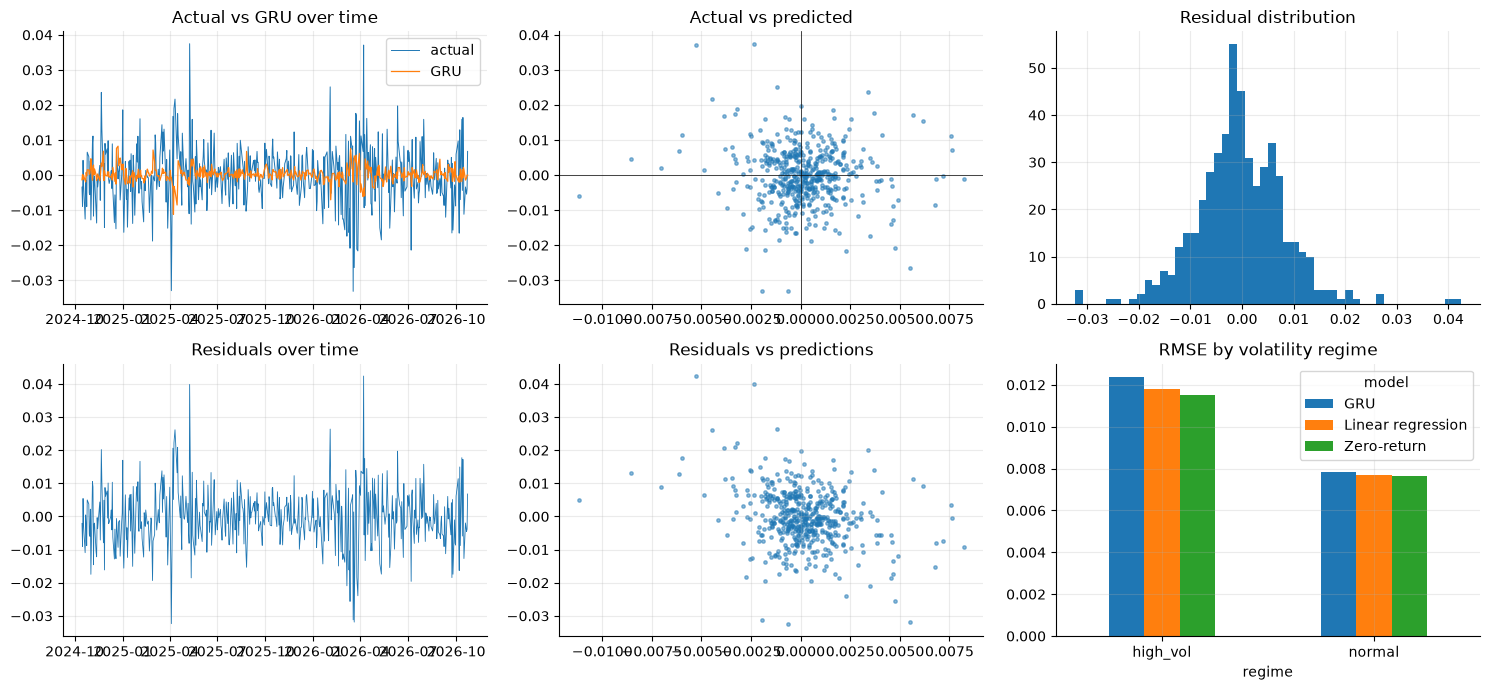

std of GRU predictions = 0.001999  vs  std of actual returns = 0.008316  (a very small ratio means the GRU is shrinking toward ~0, as expected for weak signal)


In [18]:
res = pred_df["actual"] - pred_df["gru"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
ax[0, 0].plot(pred_df.date, pred_df.actual, lw=.7, label="actual"); ax[0, 0].plot(pred_df.date, pred_df.gru, lw=.9, label="GRU"); ax[0, 0].legend(); ax[0, 0].set_title("Actual vs GRU over time")
ax[0, 1].scatter(pred_df.gru, pred_df.actual, s=6, alpha=.5); ax[0, 1].axhline(0, c="k", lw=.5); ax[0, 1].axvline(0, c="k", lw=.5); ax[0, 1].set_title("Actual vs predicted")
ax[0, 2].hist(res, bins=50); ax[0, 2].set_title("Residual distribution")
ax[1, 0].plot(pred_df.date, res, lw=.6); ax[1, 0].set_title("Residuals over time")
ax[1, 1].scatter(pred_df.gru, res, s=6, alpha=.5); ax[1, 1].set_title("Residuals vs predictions")
rr = regime_df[regime_df.regime != "all"].pivot(index="regime", columns="model", values="RMSE"); rr.plot.bar(ax=ax[1, 2], rot=0); ax[1, 2].set_title("RMSE by volatility regime")
plt.tight_layout(); plt.show()
print(f"std of GRU predictions = {pred_df.gru.std():.6f}  vs  std of actual returns = {pred_df.actual.std():.6f}  (a very small ratio means the GRU is shrinking toward ~0, as expected for weak signal)")

## 20. Visualisation of results

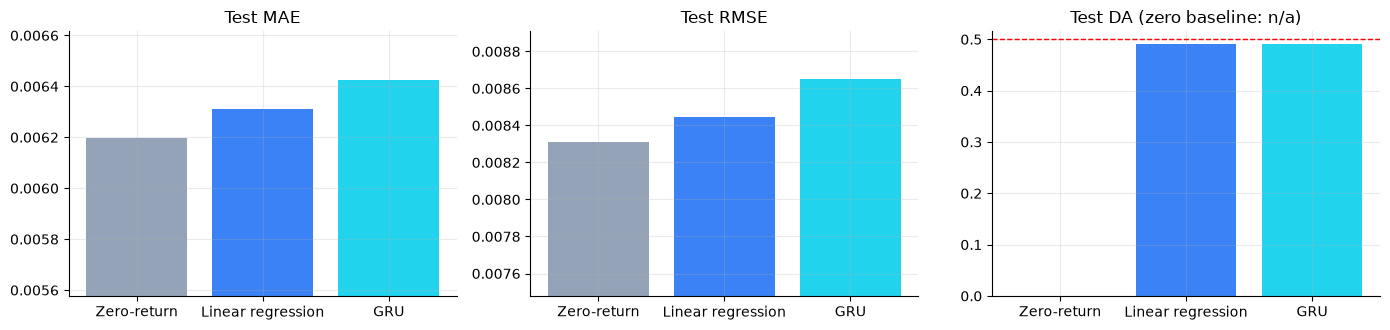

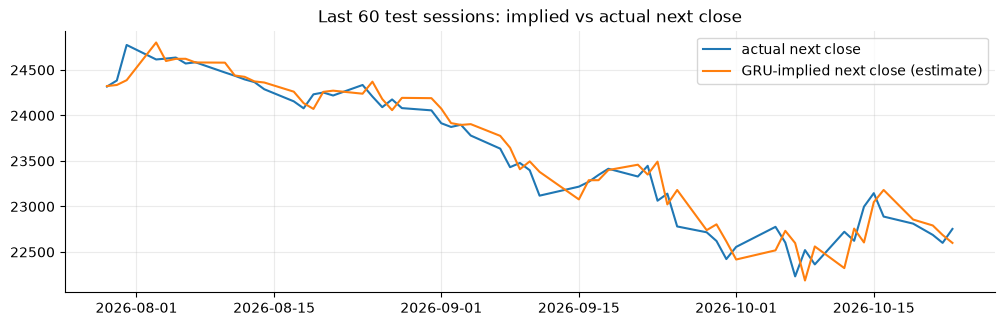

In [19]:
ct = comp["test"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, m in zip(ax, ["MAE", "RMSE", "DA"]):
    a.bar(ct["model"], ct[m].fillna(0), color=["#94a3b8", "#3b82f6", "#22d3ee"]); a.set_title(f"Test {m}" + (" (zero baseline: n/a)" if m == "DA" else ""))
    if m != "DA": a.set_ylim(ct[m].min() * 0.9, ct[m].max() * 1.03)
    else: a.axhline(0.5, c="r", ls="--", lw=1)
plt.tight_layout(); plt.show()
implied = df["Close"].reindex(pred_df.date).values * np.exp(pred_df.gru.values)
actual_next = df["Close"].reindex(pred_df.date).values * np.exp(pred_df.actual.values)
plt.figure(figsize=(12, 3.4)); plt.plot(pred_df.date.iloc[-60:], actual_next[-60:], label="actual next close"); plt.plot(pred_df.date.iloc[-60:], implied[-60:], label="GRU-implied next close (estimate)")
plt.title("Last 60 test sessions: implied vs actual next close"); plt.legend(); plt.show()

## 21. Saving and reloading artifacts
Everything the dashboard needs is written by this pipeline (no hand-made files): model, scaler, linear baseline, metadata, experiment log, history, predictions and comparison tables. The saved model is **reloaded and checked against the in-memory model**.

In [20]:
model.save(ART / "gru_model.keras")
joblib.dump(scaler, ART / "scaler.joblib"); joblib.dump(lin, ART / "linear_baseline.joblib")
experiments.to_csv(ART / "experiments.csv", index=False); history_df.to_csv(ART / "history.csv", index=False)
sp = lambda k: dict(start=str(S[k]["dates"][0].date()), end=str(S[k]["dates"][-1].date()), n=int(len(S[k]["y"])))
metadata = dict(
    project="NeuroSentinel", trained_at_utc=datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC"), data_retrieved_at=RETRIEVED_AT,
    ticker=CFG["ticker"], data_start=str(df.index.min().date()), data_end=str(df.index.max().date()), n_clean_rows=int(len(df)),
    features=FEATURES, lookback=L, y_scale=y_scale, config=CFG, high_vol_threshold=HV_THRESHOLD, n_experiments=int(len(experiments)),
    selected=dict(config=best_id, optimizer=best_row.optimizer, loss=best_row.loss, seed=int(best_row.seed), val_rmse=float(best_row.val_rmse), epochs_run=int(best_row.epochs_run)),
    splits=dict(train=sp("train"), val=sp("val"), test=sp("test")),
    metrics_test=comp["test"].set_index("model")[["MAE", "RMSE", "DA"]].to_dict("index"), versions=VERSIONS,
)
(ART / "metadata.json").write_text(json.dumps(metadata, indent=2, default=str), encoding="utf-8")
print("saved:", sorted(p.name for p in ART.iterdir()))

saved: ['comparison_test.csv', 'comparison_val.csv', 'dm_tests_test.csv', 'experiments.csv', 'gru_model.keras', 'history.csv', 'linear_baseline.joblib', 'metadata.json', 'raw_data_snapshot.csv', 'scaler.joblib', 'test_predictions.csv', 'volatility_regime_test.csv']


In [21]:
reloaded = keras.saving.load_model(ART / "gru_model.keras", compile=False)
scaler2 = joblib.load(ART / "scaler.joblib"); meta2 = json.loads((ART / "metadata.json").read_text())

def a_files():
    need = ["gru_model.keras", "scaler.joblib", "linear_baseline.joblib", "metadata.json", "experiments.csv", "history.csv",
            "test_predictions.csv", "comparison_val.csv", "comparison_test.csv", "volatility_regime_test.csv"]
    miss = [f for f in need if not (ART / f).exists() or (ART / f).stat().st_size == 0]; assert not miss, miss
def a_schema(): assert meta2["features"] == FEATURES and meta2["lookback"] == L and reloaded.input_shape == (None, L, len(FEATURES))
def a_roundtrip():
    a = gru_predict(model, S["test"]["X"]); b = reloaded.predict(S["test"]["X"], batch_size=512, verbose=0).ravel() * meta2["y_scale"]
    assert np.allclose(a, b, atol=1e-5), np.abs(a - b).max()
def a_scaler(): assert np.allclose(scaler2.transform(Xdf.values[:50]), Xs[:50])
def a_preds_period():
    p = pd.read_csv(ART / "test_predictions.csv", parse_dates=["date"])
    assert p.date.min() == pd.Timestamp(meta2["splits"]["test"]["start"]) and p.date.max() == pd.Timestamp(meta2["splits"]["test"]["end"]) and len(p) == meta2["splits"]["test"]["n"]
def a_metrics_consistent():
    p = pd.read_csv(ART / "test_predictions.csv"); g = metrics(p.actual, p.gru); c = pd.read_csv(ART / "comparison_test.csv").set_index("model")
    assert np.isclose(g["RMSE"], c.loc["GRU", "RMSE"]) and np.isclose(g["MAE"], c.loc["GRU", "MAE"])
for n, f in [("all artifact files exist and are non-empty", a_files), ("metadata feature schema matches pipeline", a_schema),
             ("saved model reload reproduces predictions", a_roundtrip), ("saved scaler reproduces transform", a_scaler),
             ("saved predictions match recorded test period", a_preds_period), ("saved predictions reproduce comparison table", a_metrics_consistent)]:
    run_test("artifacts", n, f)
tests_df = show_tests(); tests_df.to_csv(ART / "test_results.csv", index=False); tests_df

30 passed, 0 failed of 30


,group,test,result,detail
0,data,non-empty dataset,PASS,
1,data,dates sorted,PASS,
2,data,no duplicate dates,PASS,
3,data,required columns,PASS,
4,data,prices positive & finite,PASS,
5,data,zero volume treated as missing,PASS,
6,features,expected feature columns,PASS,
7,features,features finite after warm-up,PASS,
8,features,lagged features aligned,PASS,
9,features,rolling window uses past only,PASS,


## 22. Live inference demonstration
Fresh data are downloaded, cleaned, featurised with the **same** functions, and passed through the **saved** model: *no retraining, no online learning*. The data date and the model's training period are shown separately. If the download fails, the cell says so and produces no forecast.

In [22]:
def forecast_latest(df_clean, model, scaler, meta):
    feats = build_features(df_clean, add_target=False).dropna(subset=meta["features"])
    win = feats[meta["features"]].iloc[-meta["lookback"]:]
    X = scaler.transform(win.values)[None, :, :]
    yhat = float(model.predict(X, verbose=0).ravel()[0] * meta["y_scale"])
    return yhat, win.index[-1], float(df_clean.loc[win.index[-1], "Close"])

try:
    stamp = datetime.now(IST).strftime("%Y-%m-%d %H:%M:%S IST")
    live_raw = fetch_nifty(CFG["ticker"], (datetime.now() - timedelta(days=220)).strftime("%Y-%m-%d"))
    live_df, live_rep = clean_ohlcv(live_raw)
    yhat, asof, c_t = forecast_latest(live_df, reloaded, scaler2, meta2)
    print(f"retrieved      : {stamp}")
    print(f"latest session : {asof.date()}  (model trained on data through {meta2['splits']['train']['end']}; NOT retrained)")
    print(f"last close C_t : {c_t:,.2f}")
    print(f"predicted next-session log return : {yhat:+.6f}  ({yhat*100:+.4f}%)   <- model estimate")
    print(f"implied next close C_t*exp(y_hat) : {c_t*np.exp(yhat):,.2f}   <- estimate, not a guarantee")
    LIVE_OK = True
except Exception as e:
    LIVE_OK = False; print("LIVE FORECAST UNAVAILABLE:", type(e).__name__, e)

retrieved      : 2026-10-26 19:35:27 IST
latest session : 2026-10-26  (model trained on data through 2022-10-03; NOT retrained)
last close C_t : 22,753.20
predicted next-session log return : +0.000272  (+0.0272%)   <- model estimate
implied next close C_t*exp(y_hat) : 22,759.40   <- estimate, not a guarantee


## 23. Limitations and conclusions
**Verdict generated from this run's saved results (nothing hand-typed):**

In [23]:
t = comp["test"].set_index("model"); r = regime_df[(regime_df.regime == "high_vol")].set_index("model")
g, z, l_ = t.loc["GRU"], t.loc["Zero-return"], t.loc["Linear regression"]
print(f"Test sessions: {int(g.n)} ({meta2['splits']['test']['start']} -> {meta2['splits']['test']['end']})")
print(f"RMSE  zero={z.RMSE:.6f}  linear={l_.RMSE:.6f}  GRU={g.RMSE:.6f}")
print(f"MAE   zero={z.MAE:.6f}  linear={l_.MAE:.6f}  GRU={g.MAE:.6f}")
print(f"DA    linear={l_.DA:.3f}  GRU={g.DA:.3f}  (50% = coin flip)")
print(f"High-vol RMSE ({int(r.loc['GRU'].n)} sessions): zero={r.loc['Zero-return'].RMSE:.6f}  GRU={r.loc['GRU'].RMSE:.6f}")
p_zg = dm_df.iloc[0].p_value
if g.RMSE < z.RMSE and p_zg < 0.05:
    print(f"\n-> GRU beats the zero baseline on test RMSE and the difference is distinguishable from noise (DM p={p_zg:.3f}, unadjusted).")
elif g.RMSE < z.RMSE:
    print(f"\n-> GRU has a lower test RMSE than the zero baseline, but the gap is NOT statistically distinguishable from noise (DM p={p_zg:.3f}). No superiority claim.")
else:
    print(f"\n-> GRU does NOT beat the zero-return baseline on test RMSE (DM p={p_zg:.3f}). No forecasting advantage was demonstrated.")
if abs(g.DA - 0.5) < 0.03: print("-> Directional accuracy is within ~3 points of 50%: no meaningful directional skill.")

Test sessions: 501 (2024-10-15 -> 2026-10-23)
RMSE  zero=0.008310  linear=0.008444  GRU=0.008649
MAE   zero=0.006197  linear=0.006312  GRU=0.006423
DA    linear=0.491  GRU=0.491  (50% = coin flip)
High-vol RMSE (74 sessions): zero=0.011498  GRU=0.012391

-> GRU does NOT beat the zero-return baseline on test RMSE (DM p=0.003). No forecasting advantage was demonstrated.
-> Directional accuracy is within ~3 points of 50%: no meaningful directional skill.


### Limitations
1. **Market unpredictability:** daily index returns contain little exploitable signal; the zero forecast is a hard benchmark for RMSE.
2. **Non-stationarity:** relationships learned on 2013–2022-ish data may not hold later.
3. **Feature limits:** OHLC-derived technical features omit macro, news, flows and microstructure.
4. **Provider limits:** Yahoo's index volume is unreliable (zeros), timestamps and revisions are outside our control; a live row may be an in-progress session.
5. **Model-selection bias:** 12 configurations were compared on one validation window.
6. **Evaluation uncertainty:** small metric gaps are not evidence; the DM test here is exploratory and uses a single test split.
7. **Trading:** accuracy ≠ profitability. No transaction costs, sizing, turnover or risk were modelled, and no backtest was performed.
8. **Live data:** feeding new rows to the saved model does not retrain or improve it.

## 24. Viva preparation and references
**Likely questions**
* *Why log returns?* Scale-free, additive across time, standard in finance; raw levels are non-stationary.
* *Where could leakage creep in and how is it blocked?* Scaler fit, shuffling, rolling features that peek forward, target alignment. See tests in §17, esp. the future-perturbation test.
* *Why does `ret_lag_0` not leak?* It is the return of session $t$ itself, known at its close; the target is the return of $t+1$.
* *Why is the zero baseline strong?* Returns have mean ≈ 0 and low signal-to-noise; any model that adds variance without signal raises RMSE.
* *Why scale the target?* Raw returns are ~1e-2, which makes MSE gradients tiny; metrics are still reported in original units.
* *Why GRU not LSTM?* Fewer parameters (2 gates vs 3), a better fit to ~3k samples; comparable accuracy on short sequences.
* *Why not claim success on DA?* DA ignores magnitude, costs, risk; and ~50% is chance.
* *Why DM test?* To ask whether an RMSE gap exceeds sampling noise. Limitation: one split, no multiple-comparison adjustment.

**References:** Cho et al. (2014), *Learning Phrase Representations using RNN Encoder–Decoder* (GRU) · Diebold & Mariano (1995), *Comparing Predictive Accuracy*, JBES · Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* · `yfinance`, TensorFlow/Keras, scikit-learn documentation.